In [93]:
from UMA_23L.main import Node, buildTree, predict
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.read_csv("./mushrooms.csv")
train_data, test_data = train_test_split(data, test_size=0.5, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

<Axes: xlabel='class', ylabel='Count'>

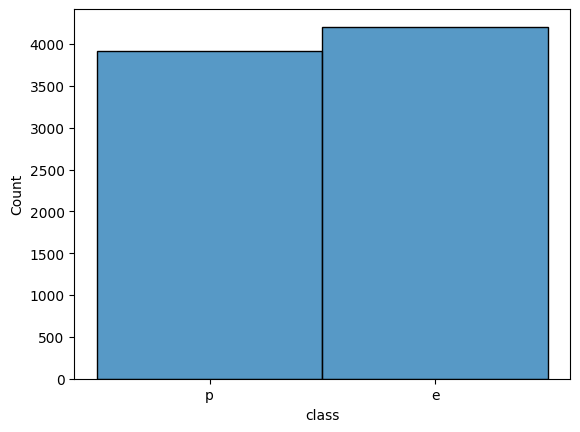

In [94]:
import seaborn
seaborn.histplot(data["class"])

In [95]:
Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())

initial_tree = Node(Node.all_attributes)

# train tree by batch
tree_batch = buildTree(train_data, initial_tree)

# train tree by single instances
# for i, row in data.iterrows():
#     r_df = pd.DataFrame(row.to_frame().T)
#     tree = buildTree(r_df, tree)

y_pred = predict(test_data, tree_batch)

In [96]:
from sklearn.metrics import accuracy_score
accuracy_score(test_data["class"], y_pred)

1.0

In [97]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier()
a = pd.get_dummies(X_train)
c = pd.get_dummies(X_test)
b = pd.get_dummies(Y_train)
classifier.fit(a, b)

DecisionTreeClassifier()

In [98]:
y_pred = classifier.predict(c)

In [ ]:
accuracy_score(y_pred, y_pred)